Filename : notebook_01.ipynb <br>
Description : Data Exploration

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

<small>1. Generate Sample data

In [2]:
data = {
    "Cust_ID": list(range(1, 16)),
    "Age": [25, 32, 40, 28, 35, 45, 50, 29, 31, 38, 42, 27, 33, 36, 48],
    "Income": [25000, 32000, 45000, 28000, 35000, 60000, 72000, 
               30000, 31000, 40000, 52000, 27000, 33000, 36000, 80000],
    "Spend_SCR": [60, 70, 55, 65, 75, 80, 90, 
                       50, 68, 72, 85, 58, 66, 74, 95],
    "Gender": ["F","M","M","M","F","M","M","F","F","M","M","F","F","M","F"],
    "Join_Date": pd.date_range("2020-01-01", periods=15, freq="ME"),
    "Is_Member": [True, True, False, True, False, True, True, 
                  False, True, True, False, True, False, True, True]
}

df = pd.DataFrame(data)
print(df)

    Cust_ID  Age  Income  Spend_SCR Gender  Join_Date  Is_Member
0         1   25   25000         60      F 2020-01-31       True
1         2   32   32000         70      M 2020-02-29       True
2         3   40   45000         55      M 2020-03-31      False
3         4   28   28000         65      M 2020-04-30       True
4         5   35   35000         75      F 2020-05-31      False
5         6   45   60000         80      M 2020-06-30       True
6         7   50   72000         90      M 2020-07-31       True
7         8   29   30000         50      F 2020-08-31      False
8         9   31   31000         68      F 2020-09-30       True
9        10   38   40000         72      M 2020-10-31       True
10       11   42   52000         85      M 2020-11-30      False
11       12   27   27000         58      F 2020-12-31       True
12       13   33   33000         66      F 2021-01-31      False
13       14   36   36000         74      M 2021-02-28       True
14       15   48   80000 

<small>2. Generate Histogram

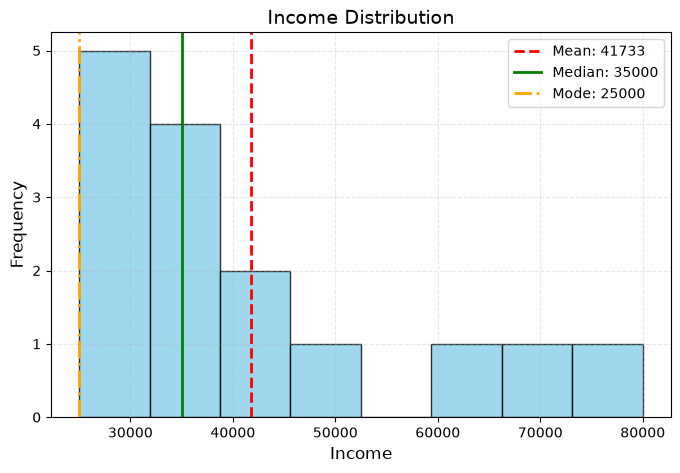

In [3]:
# Calculate Mean, Median, Mode
mean_val = df["Income"].mean()
median_val = df["Income"].median()
mode_val = (df["Income"]).mode()[0]

# Set plot style as default
plt.style.use("default")

# Create Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Income"], bins=8, color="skyblue", edgecolor="black", alpha=0.8)

# Add line Mean, Median, Mode
plt.axvline(mean_val, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.0f}")
plt.axvline(median_val, color="green", linestyle="-", linewidth=2, label=f"Median: {median_val:.0f}")
plt.axvline(mode_val, color="orange", linestyle="-.", linewidth=2, label=f"Mode: {mode_val:.0f}")

# Add other graph components
plt.title("Income Distribution", fontsize=14)
plt.xlabel("Income", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis="both", alpha=0.3, linestyle="--")

plt.show()

<small>3. Generate Box-plot

/var/folders/68/xgtcn7w51cvbbzv51djkq1300000gn/T/ipykernel_10478/1707100420.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[feature], vert=True, patch_artist=True,


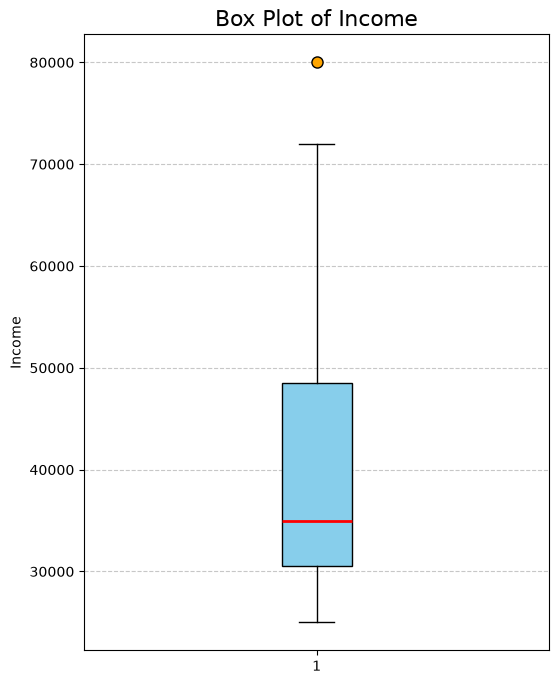

In [4]:
feature = "Income"

# Create Box Plot 
plt.figure(figsize=(6, 8))
plt.boxplot(df[feature], vert=True, patch_artist=True,
            boxprops=dict(facecolor="skyblue", color="black"),
            medianprops=dict(color="red", linewidth=2),
            whiskerprops=dict(color="black", linewidth=1),
            capprops=dict(color="black", linewidth=1),
            flierprops=dict(markerfacecolor="orange", marker="o", markersize=8))

plt.title(f"Box Plot of {feature}", fontsize=16)
plt.ylabel(feature)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

<small> 4. Generate Bar Chart

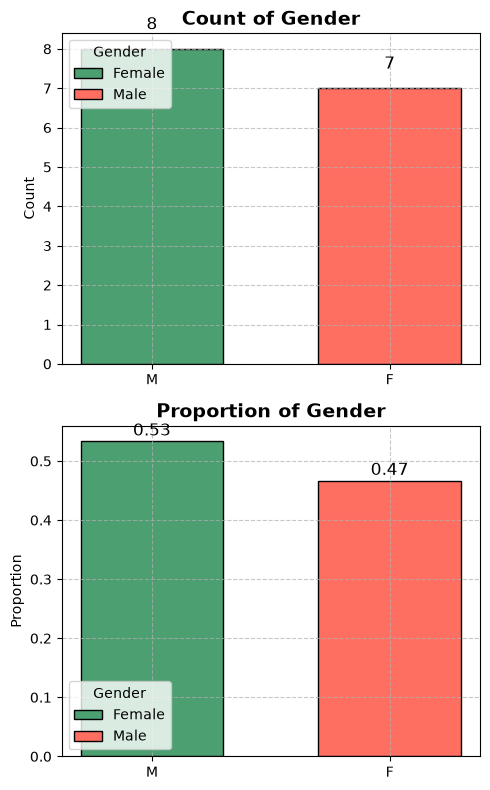

In [5]:
# --- Frequency Distribution for Gender ---
freq = df['Gender'].value_counts()
prop = df['Gender'].value_counts(normalize=True)

# --- Plot Vertical Bar Charts ---
fig, ax = plt.subplots(2, 1, figsize=(5, 8))

ax[0].bar(freq.index, freq.values, 
          color=['#4C9F70', '#FF6F61'], 
          edgecolor="black", width=0.6,
          label=["Female","Male"])   
ax[0].set_title("Count of Gender", fontsize=14, weight="bold")
ax[0].set_ylabel("Count")
ax[0].grid(True, linestyle="--", alpha=0.7)
ax[0].legend(title="Gender")        
for i, v in enumerate(freq.values):
    ax[0].text(i, v + 0.5, str(v), ha='center', fontsize=12)

# Proportion chart
ax[1].bar(prop.index, prop.values, 
          color=['#4C9F70', '#FF6F61'], 
          edgecolor="black", width=0.6,
          label=["Female","Male"])   
ax[1].set_title("Proportion of Gender", fontsize=14, weight="bold")
ax[1].set_ylabel("Proportion")
ax[1].grid(True, linestyle="--", alpha=0.7)
ax[1].legend(title="Gender")        
for i, v in enumerate(prop.values):
    ax[1].text(i, v + 0.01, f"{v:.2f}", ha='center', fontsize=12)

plt.tight_layout()
plt.show()

<small> 5. Generate Scatter-Plot

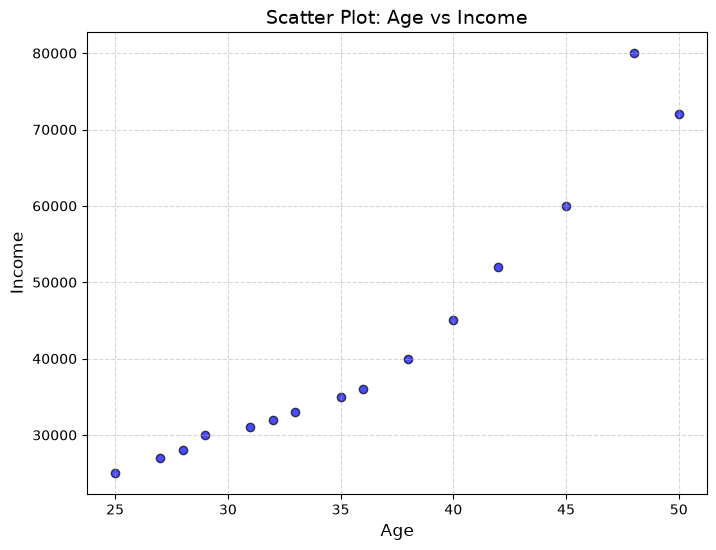

In [6]:
# สร้าง Scatter Plot: Age vs Income
plt.figure(figsize=(8, 6))
plt.scatter(df["Age"], df["Income"], c="blue", alpha=0.7, edgecolors="black")

# ตกแต่งกราฟ
plt.title("Scatter Plot: Age vs Income", fontsize=14)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Income", fontsize=12)
plt.grid(True, axis="both", linestyle="--", alpha=0.5)

plt.show()

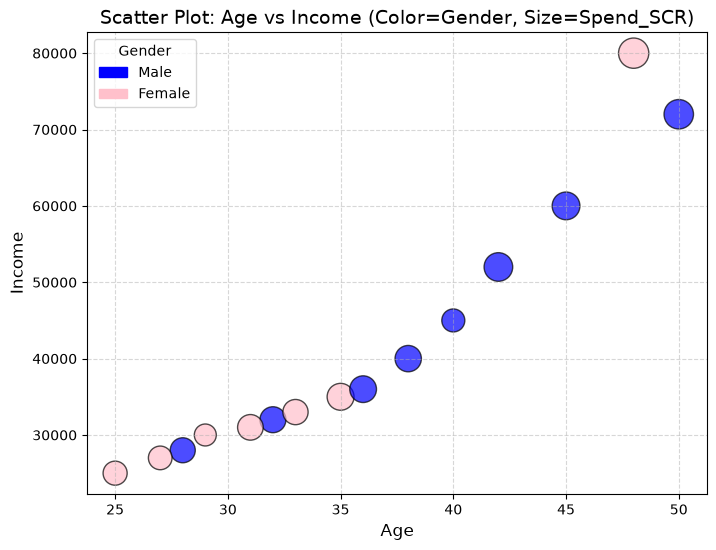

In [7]:
# Define color for gender
colors = df["Gender"].map({"M": "blue", "F": "pink"})

# Define size for Spending Score (Adjust scale)
sizes = df["Spend_SCR"] * 5

# Create Scatter Plot: Age vs Income
plt.figure(figsize=(8, 6))
plt.scatter(df["Age"], df["Income"], c=colors, s=sizes, alpha=0.7, edgecolors="black")

# Details
plt.title("Scatter Plot: Age vs Income (Color=Gender, Size=Spend_SCR)", fontsize=14)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Income", fontsize=12)
plt.grid(True, axis="both", linestyle="--", alpha=0.5)

# Legend for Gender
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color="blue", label="Male"),
    mpatches.Patch(color="pink", label="Female")
]
plt.legend(handles=legend_handles, title="Gender", fontsize=10)

plt.show()

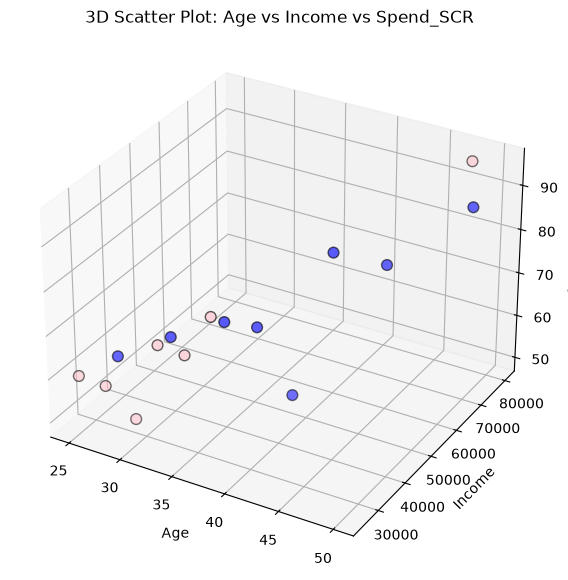

In [8]:
from mpl_toolkits.mplot3d import Axes3D

# กำหนดสีตาม Gender
colors = df["Gender"].map({"M": "blue", "F": "pink"})

# สร้าง 3D Scatter Plot: Age vs Income vs Spend_SCR
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["Age"], df["Income"], df["Spend_SCR"],
           c=colors, s=60, alpha=0.8, edgecolors="black")

# ตกแต่งแกน
ax.set_xlabel("Age")
ax.set_ylabel("Income")
ax.set_zlabel("Spend_SCR")
ax.set_title("3D Scatter Plot: Age vs Income vs Spend_SCR")

plt.show()

In [9]:
import plotly.express as px

# สร้าง Interactive 3D Scatter Plot
fig = px.scatter_3d(df,
                    x="Age", y="Income", z="Spend_SCR",
                    color="Gender", symbol="Is_Member",
                    size="Spend_SCR",
                    title="Interactive 3D Scatter Plot: Age vs Income vs Spend_SCR")

fig.show()

ModuleNotFoundError: No module named 'plotly'

<small> 6. Correlation Matrix and HeatMap

In [ ]:
corr = df[["Age","Income","Spend_SCR"]].corr()

# Create Heatmap 
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")

# Insert value into each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", 
                 ha="center", va="center", color="black")

# Details
plt.xticks(range(len(corr)), corr.columns, fontsize=12)
plt.yticks(range(len(corr)), corr.columns, fontsize=12)
plt.colorbar(label="Correlation")
plt.title("Heatmap of Correlation", fontsize=14)
plt.grid(False)

plt.show()

<small> 7. Pair-Plot

In [ ]:
features = ["Age","Income","Spend_SCR"]
colors = df["Gender"].map({"M":"blue","F":"pink"})

# สร้าง Pairplot แบบ manual
fig, axes = plt.subplots(len(features), len(features), figsize=(10,10))

for i, f1 in enumerate(features):
    for j, f2 in enumerate(features):
        ax = axes[i,j]
        if i == j:
            ax.hist(df[f1], color="skyblue", edgecolor="black")
        else:
            ax.scatter(df[f2], df[f1], c=colors, alpha=0.7, edgecolors="black")
        if i == len(features)-1:
            ax.set_xlabel(f2)
        else:
            ax.set_xticks([])
        if j == 0:
            ax.set_ylabel(f1)
        else:
            ax.set_yticks([])

plt.suptitle("Pairplot (Matplotlib)", fontsize=14)
plt.tight_layout()
plt.show()

<small> 8. Pie Chart

In [ ]:
# นับจำนวนแต่ละ Gender
count_vals = df["Gender"].value_counts()

# สร้าง Pie Chart
plt.figure(figsize=(6, 6))
plt.pie(count_vals, labels=count_vals.index,
        autopct="%1.1f%%", colors=["skyblue", "salmon"],
        startangle=90)
plt.title("Pie Chart: Gender Proportion")
plt.show()

<small> 9. Grouped Bar Chart

In [ ]:
# ค่าเฉลี่ย Income แยกตาม Gender และ Is_Member
group_mean = df.groupby(["Gender","Is_Member"])["Income"].mean().unstack()

# Grouped Bar Chart
group_mean.plot(kind="bar", figsize=(8,6), color=["skyblue","salmon"], edgecolor="black")
plt.title("Grouped Bar Chart: Average Income by Gender & Membership")
plt.ylabel("Average Income")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

<small> 10. Stacked Bar Chart

In [ ]:
# Count ของ Gender และ Is_Member
group_count = df.groupby(["Gender","Is_Member"]).size().unstack()

# Stacked Bar Chart
group_count.plot(kind="bar", stacked=True, figsize=(8,6), color=["skyblue","salmon"], edgecolor="black")
plt.title("Stacked Bar Chart: Count by Gender & Membership")
plt.ylabel("Count")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# สร้าง Cross-tabulation
ct = pd.crosstab(df["Gender"], df["Is_Member"])

# Plot Heatmap
plt.figure(figsize=(6,5))
plt.imshow(ct, cmap="coolwarm", interpolation="nearest")

# เพิ่มค่าในแต่ละ cell
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        plt.text(j, i, ct.iloc[i, j], ha="center", va="center", color="black", fontsize=12)

# ตกแต่งแกน
plt.xticks(range(ct.shape[1]), ct.columns, fontsize=12)
plt.yticks(range(ct.shape[0]), ct.index, fontsize=12)
plt.colorbar(label="Count")
plt.title("Heatmap: Gender vs Membership", fontsize=14)
plt.show()

In [ ]:
from statsmodels.graphics.mosaicplot import mosaic

# สร้าง Mosaic Plot
plt.figure(figsize=(8,6))
mosaic(df, ["Gender", "Is_Member"])
plt.title("Mosaic Plot: Gender vs Membership")
plt.show()